# One feedback choice for two-point and three-point shear

Gas cooling and energetic outflows move matter inside and around halos. The
power spectrum and the bispectrum weight that redistribution differently, so a
feedback model must answer for both statistics at once. This notebook loads
**two response tables with one common amplitude**, one for the power spectrum
and one for the bispectrum, and propagates them through the same DES Y3 joint
prediction.

The example tables are artificial smooth suppressions that teach the interface
and show which parts of the prediction respond; they are not a fit to a
hydrodynamic simulation. A constraint on a calibrated feedback model needs a
documented, matched total-matter power/bispectrum pair in their place.
[Paired-response description](../../external_modules/code/cosmolike_core/cosmolike/3pcf/README.md#paired-feedback) lists public paired sources and explains the
cold-matter/total-matter distinction. The
[project acknowledgements](README.md#acknowledgements) credit the original
fastnc code and the calculations of Sugiyama and Gomes.

Prepare the generated fiducial theory table in `chains/` before evaluating this demonstration. From the activated `Cocoa/` directory:

```bash
python projects/des_3pcf/scripts/run_3pcf.py prepare \
  projects/des_3pcf/configs/des_y3_nla_demo_fisher.yaml
```

The response-construction cell below writes the artificial feedback table to `chains/` as well. The source distribution and released survey covariance remain inputs in `data/`.


**Model and data.** The settings come from the configuration and the response
file that the cells below load:

| Choice | Value |
| --- | --- |
| Configuration | `configs/des_y3_joint_feedback_demo.yaml` |
| Response tables | `chains/paired_feedback_demo.npz`, written by `demonstration_feedback_file` |
| Feedback amplitudes | $A = 0$, $0.5$, $1$ |
| Data vector | 400 two-point rows and 80 aperture rows, all kept |
| Figures | source pair (1,1) and source triple (1,1,1); files in `chains/joint_feedback/` |
| Threads | one BLAS worker; OpenMP capped at four |

Words used throughout:

- **DMO**, dark-matter-only: the gravity-only reference model, with no baryonic
  feedback applied to its power spectrum or bispectrum.
- A **response table** stores a ratio such as
  $R_P(k,z)=P_\mathrm{feedback}(k,z)/P_\mathrm{DMO}(k,z)$ on a
  wavenumber-redshift grid; multiplying the DMO prediction by the table applies
  the feedback model.
- The **feedback amplitude** $A$ interpolates between the DMO model at $A=0$
  and the full response pair at $A=1$.
- $\xi_\pm(\theta)$ are the two-point shear correlations at angular separation
  $\theta$; $\langle M_\mathrm{ap}^3(R)\rangle$ is the **aperture skewness**, the
  third moment of shear integrated with a compensated filter of radius $R$.
- **TATT**, tidal alignment and tidal torquing: the intrinsic-alignment model
  of the Y3 demonstration prediction underneath.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
from pathlib import Path
import sys
import importlib

for variable in (
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
    "OMP_NUM_THREADS",
):
    os.environ[variable] = "1"
os.environ["OMP_THREAD_LIMIT"] = "4"
PROJECT = Path.cwd()
if not (PROJECT / "README.md").is_file():
    raise ValueError("Use des_3pcf as this notebook's working directory.")
CORE = PROJECT.parents[1] / "external_modules" / "code" / "cosmolike_core"
sys.path.insert(0, str(PROJECT / "interface"))
sys.path.insert(0, str(CORE))
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
from threadpoolctl import threadpool_info, threadpool_limits
import cosmolike_des_3pcf_components_wrappers as nw
from des3pcf.feedback import demonstration_feedback_file
import run_3pcf as driver

blas_limit = threadpool_limits(limits=1, user_api="blas")
for library in threadpool_info():
    if library["user_api"] == "blas" and library["num_threads"] != 1:
        raise RuntimeError("A loaded BLAS library has more than one worker.")
plots = importlib.import_module(name="cosmolike_notebook_utils.3pcf")

In [2]:
# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90

## 1. The response family and its limits

Write $P_A=\exp(A\ln R_P)\,P_\mathrm{DMO}$ and
$B_A=\exp(A\ln R_B)\,B_\mathrm{DMO}$. The two tables define $R_P$ and $R_B$
separately; $A=0$ gives the original DMO model and $A=1$ applies the full pair.
The logarithmic interpolation keeps each ratio positive, and the amplitude
derivative is $\partial_A P_A=P_A\ln R_P$, with the analogous expression for
$B_A$. The family has one free amplitude by construction; $A$ is not the
heating temperature of an AGN (active galactic nucleus) model or any other
physical feedback parameter.

The feedback assumption modifies only the nonlinear-alignment baseline of the
IA model; the quadratic IA corrections keep their DMO spectra in both
statistics. This matches how the ordinary CFASTPT calculation, the C port of
the FAST-PT perturbation-theory code, separates its nonlinear baseline from its
linear-power loop corrections. The fixed Y3 covariance stays the configured
input, so the amplitude changes the mean prediction only.

In [3]:
response_path = demonstration_feedback_file(
    path=PROJECT / "chains/paired_feedback_demo.npz",
)
path = PROJECT / "configs/des_y3_joint_feedback_demo.yaml"
config, path, digest = driver.load_configuration(path=path, command="evaluate")
compiled = driver.compiled_extension(config=config)
rows = driver.rows_for_run(config=config, path=path)
provider, metadata = driver.provider_for_run(compiled=compiled, config=config, path=path)
prediction = driver.prediction_for_run(
    compiled=compiled, config=config, path=path, rows=rows, provider=provider,
)
print(dict(provider.feedback.metadata))


{'amplitude_model': 'log_response', 'cosmology_dependence': 'fixed_ratio', 'domain': 'clamp', 'ia_response': 'nla_only', 'matter_field': 'total', 'name': 'artificial paired response for teaching and numerical tests', 'source_url': 'FEEDBACK.md#demonstration; analytic functions, no hydro data'}


## 2. Change feedback without rerunning CAMB

The C model owns the paired response, the cosmology and the source kernels.
Changing $A$ re-evaluates the projection and the two-point nonlinear spectrum
while keeping the same DMO physical model, so no CAMB run repeats. Setting
$A=0$ again must reproduce the first prediction exactly; the cell checks that
the kernel keeps no feedback-modified state between calls.

All 400 two-point and 80 aperture rows stay present. The demonstration keeps
the same mixed inputs as the IA Fisher notebook, so its source clipping,
estimator and accuracy limits carry over unchanged.

In [4]:
means = []
for amplitude in (0., .5, 1.):
    point = dict(config["parameters"], feedback_amplitude=amplitude)
    means.append(prediction(parameters=point))
    if amplitude == 0.:
        original_owner = provider.model
    assert provider.model is original_owner
restored = prediction(parameters=dict(config["parameters"], feedback_amplitude=0.))
np.testing.assert_array_equal(restored, means[0])
print("All joint rows:", rows.values.size)
print("DMO prediction restored exactly; physical model reused:",
      provider.model is original_owner)


All joint rows: 480
DMO prediction restored exactly; physical model reused: True


## 3. Compare the observable responses

The plots show the first source auto-correlation for readability; the
calculation keeps all rows. The vertical coordinate is the percentage change
from the DMO prediction at each angular bin. $\xi_+$, $\xi_-$ and the aperture
skewness respond with different shapes because each statistic weights the
Fourier modes differently and the power and bispectrum ratios are independent
inputs. Shape differences of this kind can help a joint fit, but their size
alone is not a Fisher gain: that calculation also needs the nuisance parameters
and the cross-covariance.

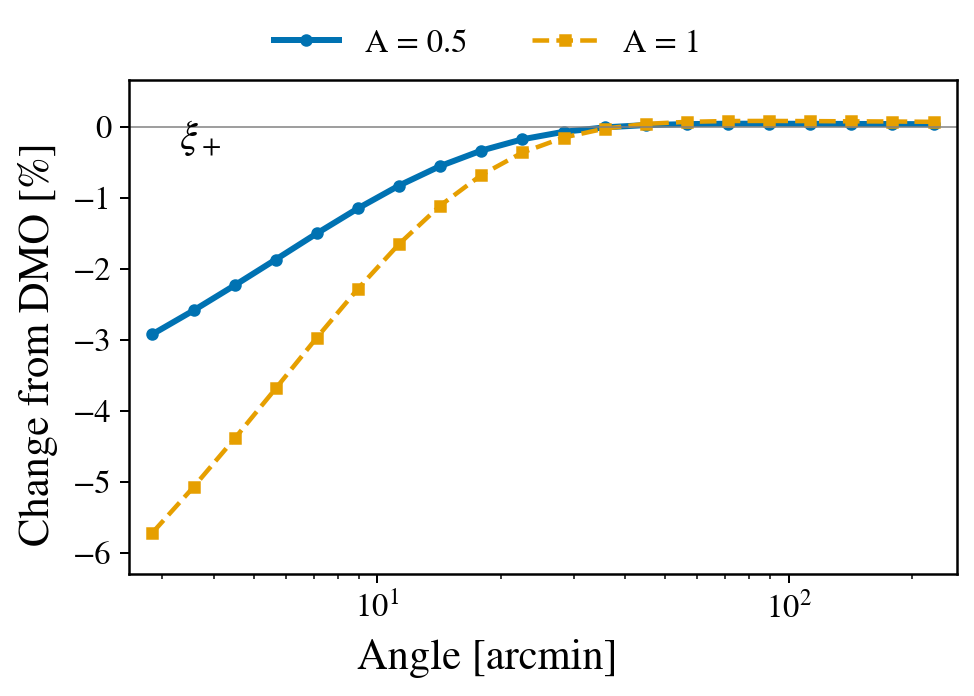

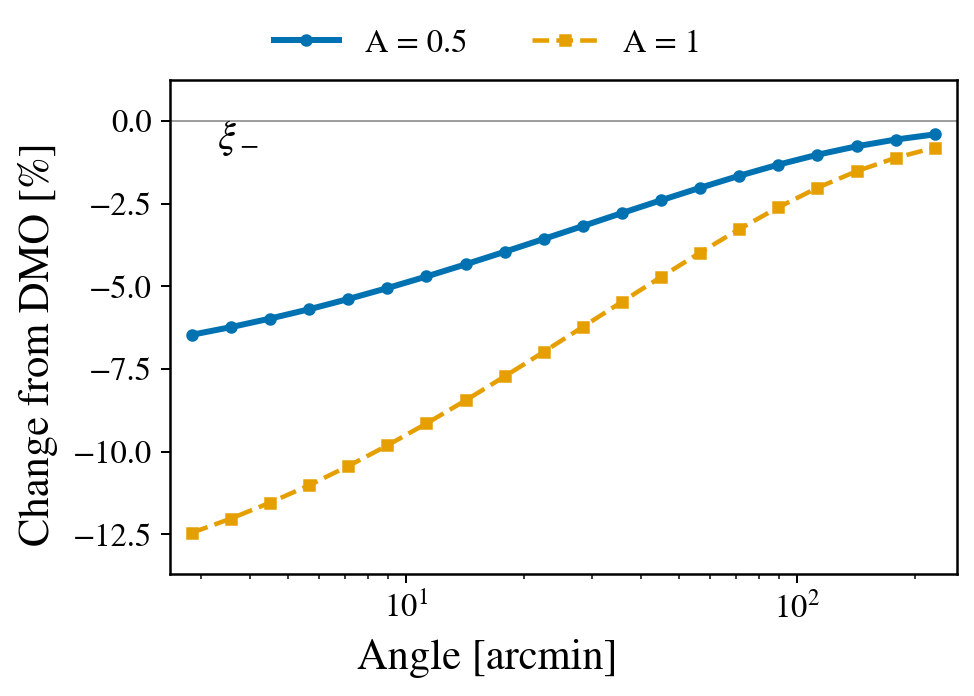

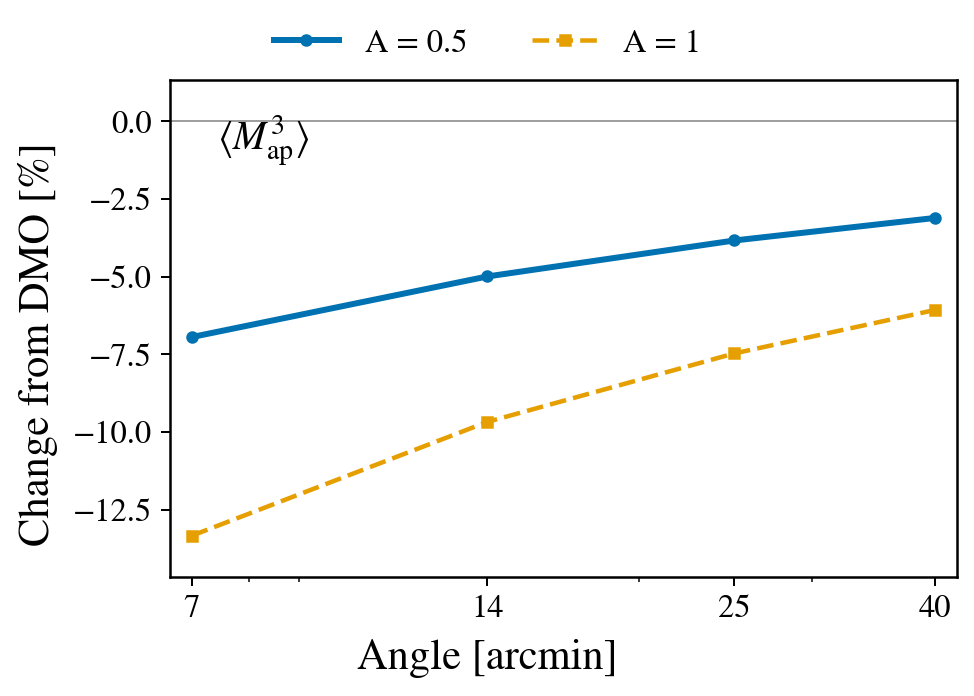

In [5]:
output = PROJECT / "chains/joint_feedback"
output.mkdir(parents=True, exist_ok=True)
for kind, label in (("xip", r"$\xi_+$"), ("xim", r"$\xi_-$"),
                    ("map3", r"$\langle M_{\rm ap}^3\rangle$")):
    selected = (rows.kind == kind) & (rows.bins[:, 0] == 0)
    selected &= rows.bins[:, 1] == 0
    if kind == "map3":
        selected &= rows.bins[:, 2] == 0
        angles = rows.angles[selected, 0]
    else:
        angles = rows.angles[selected, 2]
    angles = angles * 180. * 60. / np.pi
    curves = []
    for values in means[1:]:
        relative = 100. * (values[selected] / means[0][selected] - 1.)
        curves.append((angles, relative[None, :]))
    figure, axes = plots.plot_ia_components(
        components=curves, component_labels=[label],
        coordinate_label="Angle [arcmin]", quantity_label="Change from DMO [%]",
        legend=["A = 0.5", "A = 1"], marker=["o", "s"],
        linewidth=[2.4, 1.8], linestyle=["-", "--"],
        ncols=1, figsize=(5.3, 3.8), show=None,
    )
    # Finish constrained layout before measuring the exported labels.
    figure.canvas.draw()
    figure.savefig(output / f"feedback_{kind}.png", dpi=150,
                   bbox_inches="tight", pad_inches=0.2)
    plt.show()


## 4. Use a physical pair for an inference study

`configs/des_y3_joint_feedback_demo.yaml` lists a Fisher displacement for
`feedback_amplitude`, with the covariance held fixed by the ordinary driver. A
simulation pair that replaces the demonstration tables must match the model in
cosmology, matter species, redshift, triangle definition and documented tails.
The implementation treats the ratio as fixed when cosmology changes, so a
cosmology-dependent emulator needs freshly prepared ratios at each cosmology,
with its own validation; the implementation also assumes no identity between
total matter and cold matter.

The native tests vary constant $R_P$ and $R_B$ independently, check the
amplitude law, permute scalene triangles, change the preparation resolution and
restore state. They also verify that the actual CFASTPT quadratic terms and the
projected higher-order IA components stay fixed under this model. The pair
changes neither the ordinary core C files nor the separately specified
covariance prescription.